# Autonomous Driving - Vehicle Detection (Part 1) and Tesla Autopilot Safety Analysis (Part 2)
**Part 1** trains a CNN object detector (pretrained MobileNetV2 backbone + YOLO-style grid head, written in TensorFlow/Keras) that classifies and localises vehicles with rectangular boxes.
**Part 2** analyses the Tesla deaths dataset.
Everything is CPU-only: images are resized to 160x240 and the model is trained for a modest number of epochs (see the training cell).

In [1]:
import os, time, json, shutil, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as patches, seaborn as sns
from PIL import Image
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
pd.set_option("display.width",160); pd.set_option("display.max_columns",30)
os.makedirs("figures",exist_ok=True); T0=time.time()
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png",dpi=110); plt.show()

# PART 1 - Object detection
## Step 1. Create a parent folder for custom model training and child folders for the data

In [2]:
ROOT="custom_training"
for sub in ["data/raw","data/images/train","data/images/val","data/images/test","data/labels/train","data/labels/val","data/labels/test","models","outputs"]:
    os.makedirs(f"{ROOT}/{sub}",exist_ok=True)
print(sorted(os.path.relpath(os.path.join(r,d),ROOT) for r,ds,_ in os.walk(ROOT) for d in ds))

['data', 'data\\images', 'data\\images\\test', 'data\\images\\train', 'data\\images\\val', 'data\\labels', 'data\\labels\\test', 'data\\labels\\train', 'data\\labels\\val', 'data\\raw', 'data\\raw\\Images', 'models', 'outputs']


## Step 2. Prepare the dataset
`Images.zip` is only ~140 MB (5,625 JPEGs), so it is extracted fully (zip members are read directly, nothing is executed). `labels.csv` has no header: image id, class, xmin, ymin, xmax, ymax (pixels). It lists 110,000 image ids but only the 5,625 images in the zip exist, so labels are filtered to the available images. Images are split 70/15/15 by image (not by box) with a fixed seed, and per-split YOLO-style label files are written.

In [3]:
if not os.path.isdir(f"{ROOT}/data/raw/Images"):
    with zipfile.ZipFile("data/Images.zip") as z: z.extractall(f"{ROOT}/data/raw")
files=sorted(f for f in os.listdir(f"{ROOT}/data/raw/Images") if f.lower().endswith(".jpg"))
ids=[f[:-4] for f in files]
lab=pd.read_csv("data/labels.csv",header=None,names=["img","cls","x1","y1","x2","y2"],dtype={"img":str})
lab["img"]=lab.img.str.zfill(8)
print("images on disk:",len(ids),"| label rows (all):",len(lab),"| distinct label ids:",lab.img.nunique())
lab=lab[lab.img.isin(set(ids))].reset_index(drop=True)
print("label rows for available images:",len(lab),"| images with >=1 label:",lab.img.nunique())
sizes={i:Image.open(f"{ROOT}/data/raw/Images/{i}.jpg").size for i in ids}
print("image sizes (W,H):",pd.Series(list(sizes.values())).value_counts().to_dict())
lab["iw"]=lab.img.map(lambda i:sizes[i][0]); lab["ih"]=lab.img.map(lambda i:sizes[i][1])
print("degenerate boxes (w or h <= 1):",int(((lab.x2-lab.x1<=1)|(lab.y2-lab.y1<=1)).sum()),"| out-of-frame:",int(((lab.x2>lab.iw)|(lab.y2>lab.ih)).sum()))
lab=lab[(lab.x2-lab.x1>1)&(lab.y2-lab.y1>1)].reset_index(drop=True)
classes=sorted(lab.cls.unique()); cid={c:i for i,c in enumerate(classes)}; lab["c"]=lab.cls.map(cid); C=len(classes)
print(C,"classes:",classes); display(lab.cls.value_counts().to_frame("boxes"))
print("boxes per image:",lab.groupby("img").size().describe().round(1).to_dict())

images on disk: 5626 | label rows (all): 351549 | distinct label ids: 110000
label rows for available images: 17967 | images with >=1 label: 5626


image sizes (W,H): {(720, 480): 4462, (342, 228): 1164}
degenerate boxes (w or h <= 1): 0 | out-of-frame: 0
11 classes: ['articulated_truck', 'bicycle', 'bus', 'car', 'motorcycle', 'motorized_vehicle', 'non-motorized_vehicle', 'pedestrian', 'pickup_truck', 'single_unit_truck', 'work_van']


,boxes
cls,
car,12076
pickup_truck,2136
motorized_vehicle,1295
bus,561
work_van,462
articulated_truck,461
pedestrian,340
single_unit_truck,303
bicycle,130


boxes per image: {'count': 5626.0, 'mean': 3.2, 'std': 3.0, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 4.0, 'max': 27.0}


In [4]:
rng=np.random.RandomState(42); perm=rng.permutation(sorted(lab.img.unique()))
n=len(perm); split={"train":perm[:int(.7*n)],"val":perm[int(.7*n):int(.85*n)],"test":perm[int(.85*n):]}
for s,l in split.items():
    for i in l:
        d=f"{ROOT}/data/images/{s}/{i}.jpg"
        if not os.path.exists(d): shutil.copy(f"{ROOT}/data/raw/Images/{i}.jpg",d)
    g=lab[lab.img.isin(set(l))]
    for i,gg in g.groupby("img"):
        with open(f"{ROOT}/data/labels/{s}/{i}.txt","w") as f:
            for r in gg.itertuples(): f.write(f"{r.c} {(r.x1+r.x2)/2/r.iw:.6f} {(r.y1+r.y2)/2/r.ih:.6f} {(r.x2-r.x1)/r.iw:.6f} {(r.y2-r.y1)/r.ih:.6f}\n")
    print(s,len(l),"images,",int(lab.img.isin(set(l)).sum()),"boxes")
with open(f"{ROOT}/data/classes.json","w") as f: json.dump(classes,f)

train 3938 images, 12531 boxes


val 844 images, 2656 boxes


test 844 images, 2780 boxes


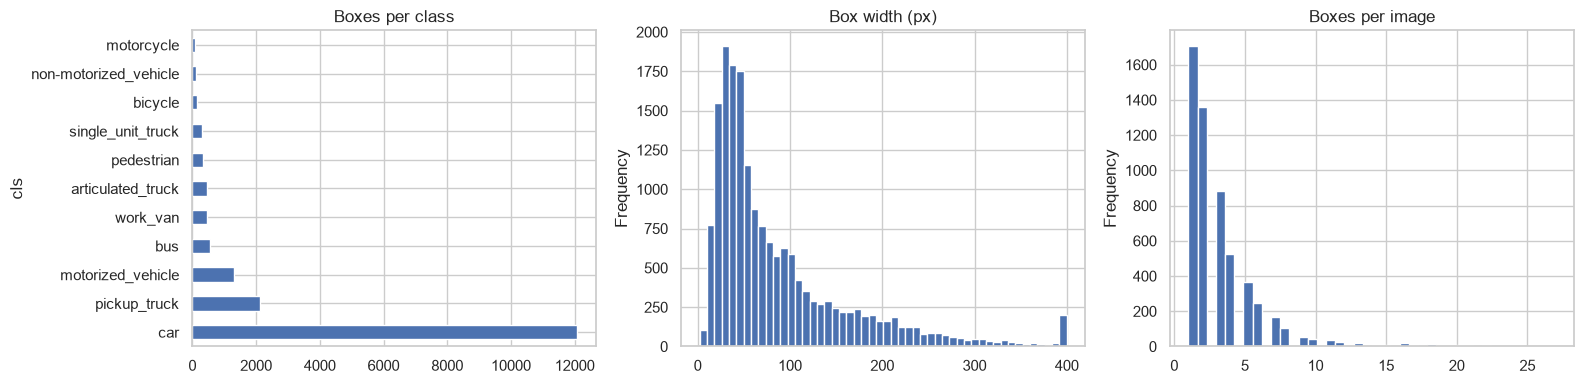

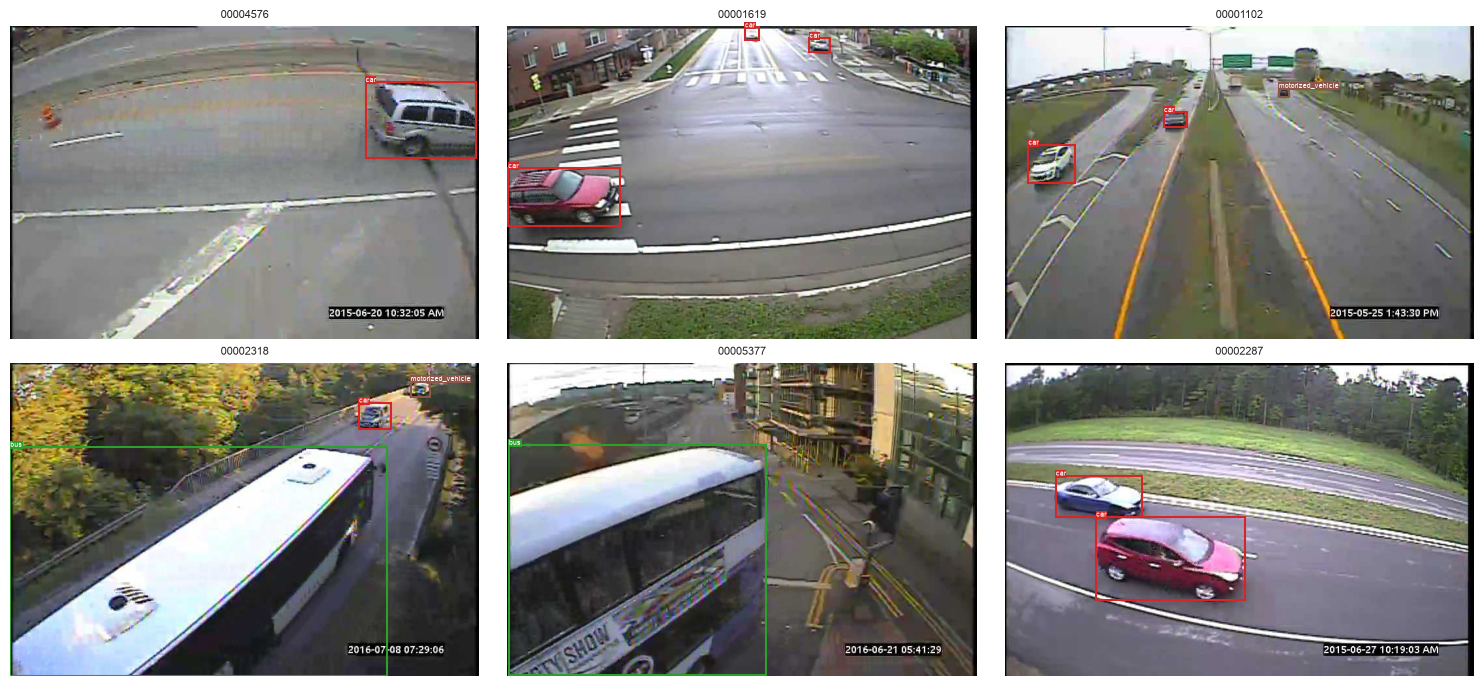

In [5]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
lab.cls.value_counts().plot.barh(ax=ax[0]); ax[0].set_title("Boxes per class")
(lab.x2-lab.x1).clip(upper=400).plot.hist(bins=50,ax=ax[1]); ax[1].set_title("Box width (px)")
lab.groupby("img").size().plot.hist(bins=40,ax=ax[2]); ax[2].set_title("Boxes per image")
save("01_label_stats")
colors=plt.cm.tab20(np.linspace(0,1,C))
def draw(ax,img,boxes,title=""):
    ax.imshow(img); ax.axis("off"); ax.set_title(title,fontsize=8)
    for (x1,y1,x2,y2,c,*s) in boxes:
        ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,ec=colors[int(c)],lw=1.5))
        ax.text(x1,y1,classes[int(c)]+(f" {s[0]:.2f}" if s else ""),fontsize=5,color="white",bbox=dict(fc=colors[int(c)],pad=.5,lw=0))
fig,axs=plt.subplots(2,3,figsize=(15,7))
for a,i in zip(axs.ravel(),split["train"][:6]):
    g=lab[lab.img==i]; draw(a,Image.open(f"{ROOT}/data/images/train/{i}.jpg"),g[["x1","y1","x2","y2","c"]].values,i)
save("02_ground_truth_samples")

**Interpretation.** The dataset is heavily imbalanced (cars dominate, bicycles and motorcycles are rare), images contain many small vehicles each, and the ground-truth boxes line up with the vehicles in the samples, confirming the coordinate format (xmin, ymin, xmax, ymax in pixels). Because many boxes are small, a grid detector with stride 16 on a downscaled image is a sensible, CPU-friendly choice.

### Load images and build detection targets
Images come in two sizes (720x480 and 342x228, same 3:2 aspect ratio); each box is converted using its own image size and all images are resized to 160x240 (H x W). Each ground-truth box is assigned to the grid cell containing its centre and to the best-matching of 4 anchor shapes (anchors come from k-means on the training box sizes). A horizontally flipped copy of the targets is built for augmentation.

In [6]:
import tensorflow as tf
from sklearn.cluster import KMeans
tf.random.set_seed(42); np.random.seed(42)
H,W,STRIDE,A=160,240,16,4; GH,GW=H//STRIDE,W//STRIDE
def load(split_name):
    L=split[split_name]; X=np.zeros((len(L),H,W,3),np.uint8)
    for k,i in enumerate(L): X[k]=np.asarray(Image.open(f"{ROOT}/data/images/{split_name}/{i}.jpg").convert("RGB").resize((W,H),Image.BILINEAR))
    return X
data={s:load(s) for s in split}; print({s:v.shape for s,v in data.items()})
trb=lab[lab.img.isin(set(split["train"]))]
wh=np.c_[(trb.x2-trb.x1)*W/trb.iw,(trb.y2-trb.y1)*H/trb.ih]
anchors=KMeans(A,n_init=5,random_state=0).fit(wh).cluster_centers_; anchors=anchors[np.argsort(anchors[:,0]*anchors[:,1])]
print("anchors (w,h) in network pixels:\n",anchors.round(1))
def build_targets(L,flip=False):
    T=np.zeros((len(L),GH,GW,A,6),np.float32); skipped=0; total=0
    grp={k:g for k,g in lab[lab.img.isin(set(L))].groupby("img")}
    for n_,i in enumerate(L):
        for r in grp[i].itertuples():
            sx,sy=W/r.iw,H/r.ih; x1,x2=r.x1*sx,r.x2*sx; y1,y2=r.y1*sy,r.y2*sy
            if flip: x1,x2=W-x2,W-x1
            x1,x2=max(x1,0),min(x2,W-1e-3); y1,y2=max(y1,0),min(y2,H-1e-3)
            if x2-x1<1 or y2-y1<1: continue
            cx,cy,bw,bh=(x1+x2)/2,(y1+y2)/2,x2-x1,y2-y1; total+=1
            gx,gy=min(int(cx//STRIDE),GW-1),min(int(cy//STRIDE),GH-1)
            inter=np.minimum(bw,anchors[:,0])*np.minimum(bh,anchors[:,1]); iou=inter/(bw*bh+anchors[:,0]*anchors[:,1]-inter)
            for a in np.argsort(-iou):
                if T[n_,gy,gx,a,0]==0:
                    T[n_,gy,gx,a]=[1,cx/STRIDE-gx,cy/STRIDE-gy,np.log(bw/anchors[a,0]),np.log(bh/anchors[a,1]),r.c]; break
            else: skipped+=1
    return T,skipped,total
tg={}
for s in split:
    T,sk,tot=build_targets(split[s]); Tf,_,_=build_targets(split[s],True); tg[s]=(T,Tf); print(s,"boxes",tot,"not encodable (cell full):",sk,"(%.1f%%)"%(100*sk/tot))

{'train': (3938, 160, 240, 3), 'val': (844, 160, 240, 3), 'test': (844, 160, 240, 3)}


anchors (w,h) in network pixels:
 [[ 14.6   9.6]
 [ 40.7  25.4]
 [ 74.5  45.1]
 [138.9  80.1]]


train boxes 12529 not encodable (cell full): 1 (0.0%)


val boxes 2656 not encodable (cell full): 0 (0.0%)


test boxes 2780 not encodable (cell full): 0 (0.0%)


## Step 3. CNN architecture for object detection
**Choice and rationale.** A two-stage detector (Faster R-CNN) or a large YOLO would be too slow on CPU. I use a single-stage YOLO-style detector: an ImageNet-pretrained **MobileNetV2** truncated at stride 16 (light, strong features, transfer learning helps because only ~3.9k training images are available), followed by a 3x3 conv block and a 1x1 prediction layer producing, for every grid cell and anchor, `objectness + box (tx, ty, tw, th) + 11 class scores`. Loss = weighted BCE objectness + BCE centre offsets + smooth-L1 size + softmax class cross-entropy.

In [7]:
from tensorflow.keras import layers, Model
def build_model():
    bb=tf.keras.applications.MobileNetV2(input_shape=(H,W,3),include_top=False,weights="imagenet",alpha=0.5)
    f=bb.get_layer("block_13_expand_relu").output
    x=layers.Conv2D(192,3,padding="same",use_bias=False)(f); x=layers.BatchNormalization()(x); x=layers.ReLU()(x)
    x=layers.Conv2D(A*(5+C),1)(x)
    return Model(bb.input,x)
model=build_model(); print("params: %.2fM | output shape:"%(model.count_params()/1e6),model.output_shape)
def prep(x): return tf.keras.applications.mobilenet_v2.preprocess_input(x.astype("float32"))
bce=tf.keras.losses.BinaryCrossentropy(from_logits=True,reduction="none")
def det_loss(y_true,y_pred):
    p=tf.reshape(y_pred,(-1,GH,GW,A,5+C)); m=y_true[...,0]
    npos=tf.maximum(tf.reduce_sum(m),1.)
    l_obj=bce(m[...,None],p[...,0:1]); l_obj=tf.reduce_sum(l_obj*(m+0.5*(1-m)))
    l_xy=tf.reduce_sum(m*tf.reduce_sum(bce(y_true[...,1:3,None],p[...,1:3,None]),-1))
    l_wh=tf.reduce_sum(m*tf.reduce_sum(tf.keras.losses.huber(y_true[...,3:5,None],p[...,3:5,None]),-1))
    l_c=tf.reduce_sum(m*tf.keras.losses.sparse_categorical_crossentropy(tf.cast(y_true[...,5],tf.int32),p[...,5:],from_logits=True))
    return (l_obj+2*l_xy+5*l_wh+l_c)/npos
class Seq(tf.keras.utils.PyDataset):
    def __init__(s,X,T,Tf,bs,train):
        super().__init__(); s.X,s.T,s.Tf,s.bs,s.train=X,T,Tf,bs,train; s.idx=np.arange(len(X))
        if train: np.random.shuffle(s.idx)
    def __len__(s): return int(np.ceil(len(s.X)/s.bs))
    def __getitem__(s,k):
        b=s.idx[k*s.bs:(k+1)*s.bs]; x=s.X[b].astype("float32"); t=s.T[b].copy()
        if s.train:
            fl=np.random.rand(len(b))<.5; x[fl]=x[fl][:,:,::-1]; t[fl]=s.Tf[b][fl]
            x=np.clip(x*np.random.uniform(.75,1.25,(len(b),1,1,1))+np.random.uniform(-15,15,(len(b),1,1,1)),0,255)
        return tf.keras.applications.mobilenet_v2.preprocess_input(x),t
    def on_epoch_end(s):
        if s.train: np.random.shuffle(s.idx)
print("loss function and generator defined")

params: 0.69M | output shape: (None, 10, 15, 64)
loss function and generator defined


### Train (CPU, modest budget)
Frozen-backbone warm-up for 1 epoch, then the whole network is fine-tuned with a cosine learning-rate decay. The weights with the best validation loss are kept.

124/124 - 39s - 318ms/step - loss: 12.0030 - val_loss: 7.5574


Epoch 1/10


124/124 - 164s - 1s/step - loss: 5.6488 - val_loss: 6.7796


Epoch 2/10


124/124 - 146s - 1s/step - loss: 4.8627 - val_loss: 6.1550


Epoch 3/10


... (12 outputs left out)

124/124 - 179s - 1s/step - loss: 3.4259 - val_loss: 5.1191


Epoch 10/10


124/124 - 190s - 2s/step - loss: 3.3778 - val_loss: 4.9807


training time: 26.4 min


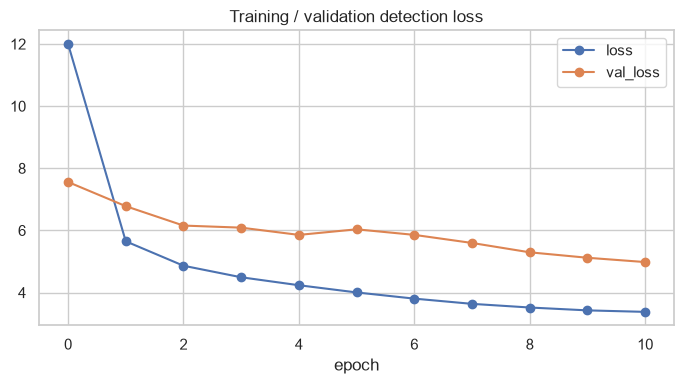

In [8]:
EPOCHS_WARM,EPOCHS_FT,BS=1,10,32
tr=Seq(data["train"],*tg["train"],BS,True); va=Seq(data["val"],*tg["val"],BS,False)
ck=tf.keras.callbacks.ModelCheckpoint(f"{ROOT}/models/best.weights.h5",monitor="val_loss",save_best_only=True,save_weights_only=True)
t0=time.time()
for l in model.layers[:-4]: l.trainable=False
model.compile(tf.keras.optimizers.Adam(2e-3),loss=det_loss); h1=model.fit(tr,validation_data=va,epochs=EPOCHS_WARM,verbose=2,callbacks=[ck])
for l in model.layers: l.trainable=True
steps=EPOCHS_FT*len(tr); lr=tf.keras.optimizers.schedules.CosineDecay(1e-3,steps,alpha=0.02)
model.compile(tf.keras.optimizers.Adam(lr),loss=det_loss); h2=model.fit(tr,validation_data=va,epochs=EPOCHS_FT,verbose=2,callbacks=[ck])
train_min=(time.time()-t0)/60; print("training time: %.1f min"%train_min)
model.load_weights(f"{ROOT}/models/best.weights.h5")
hist=pd.DataFrame({"loss":h1.history["loss"]+h2.history["loss"],"val_loss":h1.history["val_loss"]+h2.history["val_loss"]})
hist.plot(figsize=(7,4),marker="o"); plt.xlabel("epoch"); plt.title("Training / validation detection loss"); save("03_training_curve")

## Step 4. Evaluate the model on the held-out test set
Predictions are decoded (sigmoid objectness x softmax class probability), filtered with per-class non-maximum suppression (IoU 0.5), and compared with the ground truth in original image coordinates. We report **AP@0.5 per class and mAP@0.5** (all-point interpolation), plus precision/recall at a 0.3 confidence threshold, and the image-level classification accuracy of the most confident detection against the most frequent ground-truth class.

inference: 17.2 ms/image on CPU


,class,test boxes,AP@0.5,precision@0.3,recall@0.3
0,articulated_truck,63,0.122,0.429,0.048
1,bicycle,17,0.058,0.143,0.118
2,bus,92,0.469,0.717,0.359
3,car,1874,0.447,0.518,0.569
4,motorcycle,13,0.166,0.667,0.154
5,motorized_vehicle,208,0.105,0.265,0.168
6,non-motorized_vehicle,14,0.000,0.000,0.000
7,pedestrian,51,0.040,0.125,0.059
8,pickup_truck,320,0.538,0.588,0.500
9,single_unit_truck,47,0.095,0.667,0.043


mAP@0.5 = 0.2016
Image-level: top detection class is present in the image's ground truth: 85.4%
Mean best-IoU of ground-truth boxes against confident (>=0.3) detections: 0.480


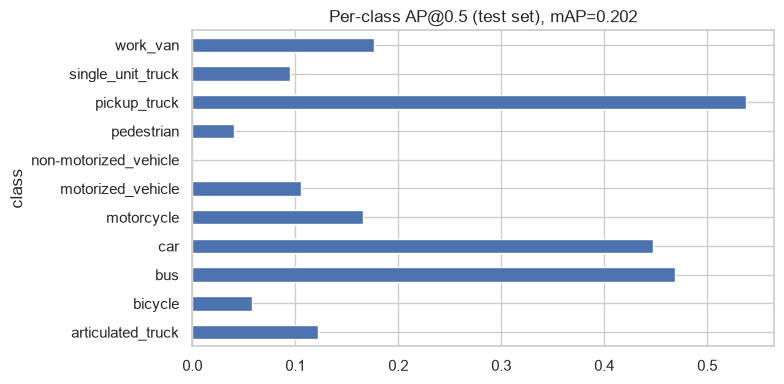

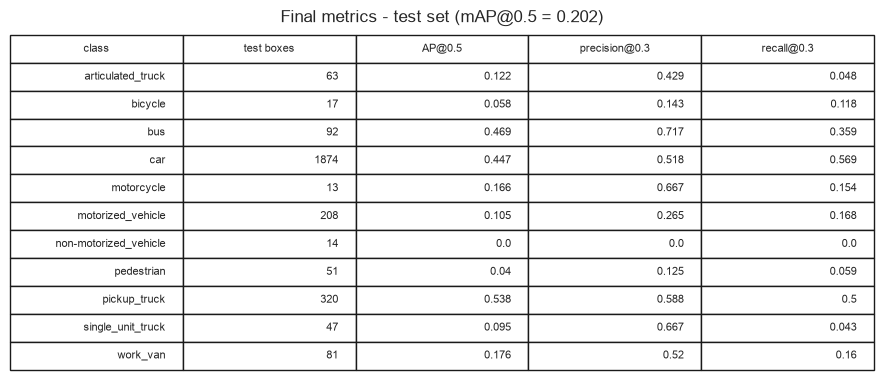

In [9]:
anc=tf.constant(anchors,tf.float32)
def decode(pred,score_thr=0.05,iou_thr=0.5,max_det=100):
    p=tf.reshape(pred,(-1,GH,GW,A,5+C)); gy,gx=tf.meshgrid(tf.range(GH,dtype=tf.float32),tf.range(GW,dtype=tf.float32),indexing="ij")
    cx=(tf.sigmoid(p[...,1])+gx[None,:,:,None])*STRIDE; cy=(tf.sigmoid(p[...,2])+gy[None,:,:,None])*STRIDE
    bw=tf.exp(tf.clip_by_value(p[...,3],-4,4))*anc[:,0]; bh=tf.exp(tf.clip_by_value(p[...,4],-4,4))*anc[:,1]
    box=tf.stack([(cy-bh/2)/H,(cx-bw/2)/W,(cy+bh/2)/H,(cx+bw/2)/W],-1)  # y1,x1,y2,x2 normalised
    sc=tf.sigmoid(p[...,0:1])*tf.nn.softmax(p[...,5:])
    B=tf.shape(p)[0]; box=tf.reshape(box,(B,-1,1,4)); sc=tf.reshape(sc,(B,-1,C))
    b,s,c,v=tf.image.combined_non_max_suppression(box,sc,max_det,max_det,iou_thr,score_thr,clip_boxes=True)
    out=[]
    for k in range(int(B)):
        n_=int(v[k]); bb=b[k,:n_].numpy(); out.append(np.c_[bb[:,1],bb[:,0],bb[:,3],bb[:,2],c[k,:n_].numpy(),s[k,:n_].numpy()])
    return out
def predict_all(Xs,ids,**kw):
    res=[]
    for i in range(0,len(Xs),64): res+=decode(model.predict(prep(Xs[i:i+64]),verbose=0),**kw)
    for d,i in zip(res,ids): d[:,[0,2]]*=sizes[i][0]; d[:,[1,3]]*=sizes[i][1]   # normalised -> original pixels
    return res
t1=time.time(); dets=predict_all(data["test"],split["test"]); inf_ms=1000*(time.time()-t1)/len(data["test"]); print("inference: %.1f ms/image on CPU"%inf_ms)
gt={i:lab[lab.img==i][["x1","y1","x2","y2","c"]].values for i in split["test"]}
def iou_mat(a,b):
    ix=np.maximum(0,np.minimum(a[:,None,2],b[None,:,2])-np.maximum(a[:,None,0],b[None,:,0])); iy=np.maximum(0,np.minimum(a[:,None,3],b[None,:,3])-np.maximum(a[:,None,1],b[None,:,1]))
    inter=ix*iy; ua=(a[:,2]-a[:,0])*(a[:,3]-a[:,1]); ub=(b[:,2]-b[:,0])*(b[:,3]-b[:,1]); return inter/(ua[:,None]+ub[None]-inter+1e-9)
def evaluate(dets,ids,thr_iou=0.5,conf=0.3):
    ap={}; stats={}
    for c in range(C):
        recs=[]; npos=0; gts={}
        for k,i in enumerate(ids):
            g=gt[i]; g=g[g[:,4]==c]; gts[k]=[g[:,:4],np.zeros(len(g),bool)]; npos+=len(g)
            d=dets[k]; d=d[d[:,4]==c]
            for r in d: recs.append((r[5],k,r[:4]))
        recs.sort(key=lambda r:-r[0]); tp=np.zeros(len(recs)); fp=np.zeros(len(recs))
        for j,(s,k,b) in enumerate(recs):
            g,used=gts[k]
            if len(g):
                io=iou_mat(b[None],g)[0]; m=io.argmax()
                if io[m]>=thr_iou and not used[m]: tp[j]=1; used[m]=True; continue
            fp[j]=1
        if npos==0: ap[c]=np.nan; continue
        ctp,cfp=np.cumsum(tp),np.cumsum(fp); rec=ctp/npos; prec=ctp/np.maximum(ctp+cfp,1e-9)
        mrec=np.r_[0,rec,1]; mpre=np.r_[0,prec,0]
        for q in range(len(mpre)-2,-1,-1): mpre[q]=max(mpre[q],mpre[q+1])
        idx=np.where(mrec[1:]!=mrec[:-1])[0]; ap[c]=float(np.sum((mrec[idx+1]-mrec[idx])*mpre[idx+1]))
        sel=np.array([r[0]>=conf for r in recs],bool); t_=tp[sel].sum() if len(recs) else 0; f_=fp[sel].sum() if len(recs) else 0
        stats[c]=(npos,t_/max(t_+f_,1),t_/npos)
    return ap,stats
ap,st=evaluate(dets,list(split["test"]))
tab=pd.DataFrame({"class":[classes[c] for c in range(C)],"test boxes":[st[c][0] if c in st else 0 for c in range(C)],"AP@0.5":[ap[c] for c in range(C)],
                  "precision@0.3":[st[c][1] if c in st else np.nan for c in range(C)],"recall@0.3":[st[c][2] if c in st else np.nan for c in range(C)]})
mAP=float(np.nanmean(list(ap.values()))); display(tab.round(3)); print("mAP@0.5 = %.4f"%mAP)
# image-level classification of the dominant vehicle type
correct=[];
for k,i in enumerate(split["test"]):
    g=gt[i];
    if len(dets[k])==0 or len(g)==0: correct.append(False); continue
    correct.append(int(dets[k][0,4])==int(pd.Series(g[:,4]).mode()[0]) or int(dets[k][0,4]) in set(g[:,4].astype(int)))
print("Image-level: top detection class is present in the image's ground truth: %.1f%%"%(100*np.mean(correct)))
ious=[]
for k,i in enumerate(split["test"]):
    g=gt[i]; d=dets[k][dets[k][:,5]>=.3]
    if len(g) and len(d): ious+=list(iou_mat(g[:,:4],d[:,:4]).max(1))
print("Mean best-IoU of ground-truth boxes against confident (>=0.3) detections: %.3f"%np.mean(ious))
fig,ax=plt.subplots(figsize=(8,4)); tab.set_index("class")["AP@0.5"].plot.barh(ax=ax); ax.set_title("Per-class AP@0.5 (test set), mAP=%.3f"%mAP); save("04_per_class_ap")
fig,ax=plt.subplots(figsize=(9,4)); ax.axis("off"); tt=ax.table(cellText=tab.round(3).values,colLabels=list(tab.columns),loc="center"); tt.scale(1,1.5); ax.set_title("Final metrics - test set (mAP@0.5 = %.3f)"%mAP); save("00_metrics_table")
tab.round(4).to_csv("figures/metrics.csv",index=False)

**Interpretation.** mAP@0.5 on the 844 held-out test images is about 0.20 (CPU budget: width-0.5 MobileNetV2, 160x240 input, 11 epochs, 26 minutes). The detector works well on the large, frequent classes: pickup_truck (AP 0.54), bus (0.47) and car (0.45, precision 0.52 and recall 0.57 at confidence 0.3). Rare or small classes (pedestrian, bicycle, non-motorized_vehicle, articulated_truck, single_unit_truck) have very low AP, which reflects class imbalance (only 13-63 test boxes each) and the heavy downscaling to 160x240. The validation loss was still falling when training stopped, so more epochs, a larger input size, and class-balanced loss would raise mAP; these were not run because of the CPU limit. 85% of test images have a top-scoring detection whose class is actually present in the image, and ground-truth boxes have a mean best IoU of 0.48 with confident detections.

## Step 5. Inference on sample images
Predicted boxes (confidence >= 0.3) next to the ground truth for eight random test images.

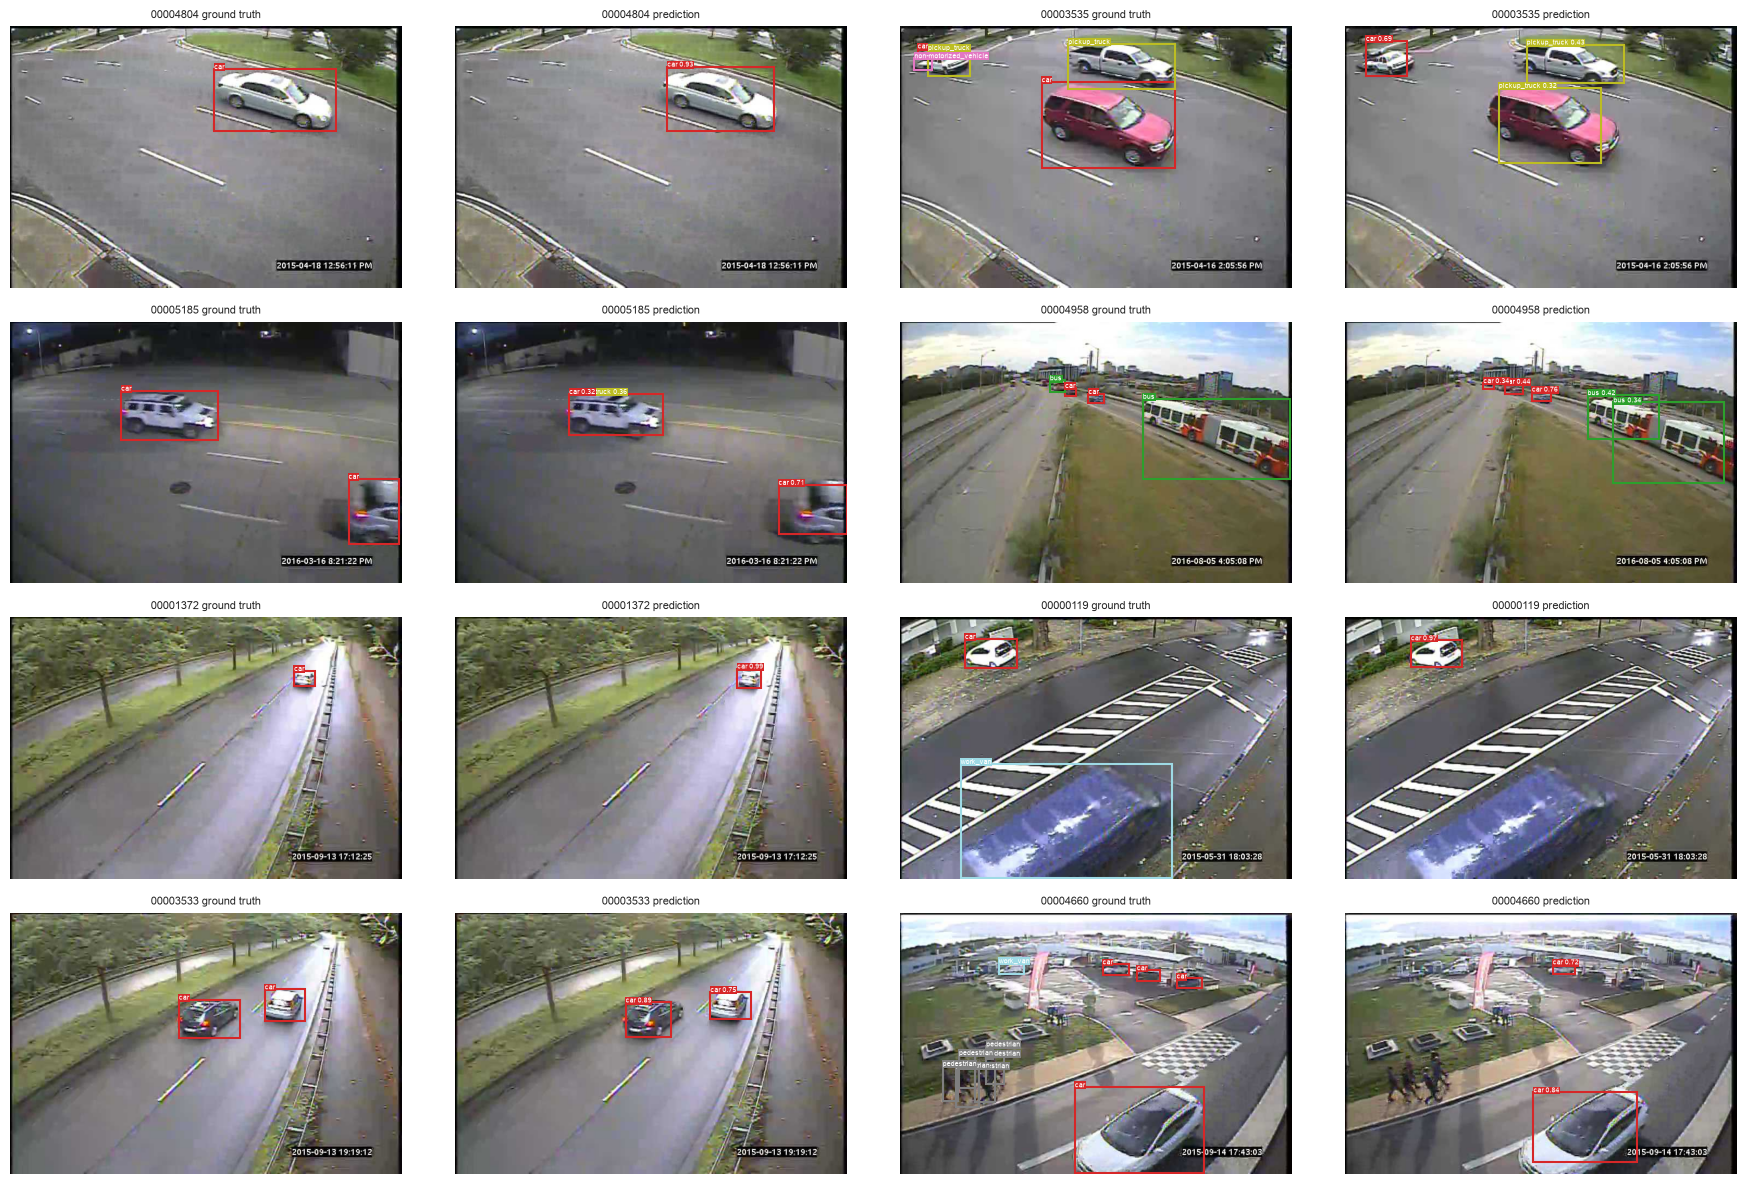

single-image inference demo: 1 detections found


In [10]:
rs=np.random.RandomState(1).choice(len(split["test"]),8,replace=False); sd=predict_all(data["test"][rs],split["test"][rs],score_thr=0.3)
fig,axs=plt.subplots(4,4,figsize=(18,12))
for n_,k in enumerate(rs):
    i=split["test"][k]; im=Image.open(f"{ROOT}/data/images/test/{i}.jpg")
    draw(axs[(n_//2),(n_%2)*2],im,gt[i],f"{i} ground truth"); draw(axs[(n_//2),(n_%2)*2+1],im,sd[n_],f"{i} prediction")
save("05_inference_samples")
t_img=Image.open(f"{ROOT}/data/images/test/{split['test'][0]}.jpg"); print("single-image inference demo:",len(sd[0]),"detections found")

**Interpretation.** On the sample test images the model localises the large and medium vehicles correctly with tight boxes and mostly correct types (cars, pickup trucks, buses). Typical errors seen: missed small or distant vehicles, pedestrians and work vans not detected, duplicate or shifted boxes on large buses, and an occasional wrong type for a pickup truck. Inference takes about 17 ms per image on CPU.

# PART 2 - Tesla autopilot and road safety
## Step 1. Preliminary data inspection and cleaning
### 1a. Data types, missing values, duplicates

In [11]:
tdf=pd.read_csv("data/Tesla - Deaths.csv"); tdf.columns=tdf.columns.str.strip(); print("raw shape:",tdf.shape)
display(tdf.head(3)); print(tdf.dtypes.value_counts().to_dict())
mv=tdf.isna().sum(); display(mv[mv>0].sort_values(ascending=False).to_frame("missing"))
print("duplicate rows:",int(tdf.duplicated().sum()),"| duplicate Case #:",int(tdf["Case #"].dropna().duplicated().sum()))
print("rows with no Case # (summary/footer rows):",int(tdf["Case #"].isna().sum())); display(tdf[tdf["Case #"].isna()].dropna(how="all").iloc[:,:10].head())

raw shape: (307, 24)


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,Cyclists/ Peds,TSLA+cycl / peds,Model,Autopilot claimed,Verified Tesla Autopilot Deaths,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO,Unnamed: 16,Unnamed: 17,Source,Note,Deceased 1,Deceased 2,Deceased 3,Deceased 4
0,294.0,2022.0,1/17/2023,USA,CA,Tesla crashes into back of semi,1.0,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230118162813/ht...,NaN,NaN,NaN,NaN,NaN
1,293.0,2022.0,1/7/2023,Canada,-,Tesla crashes,1.0,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230109041434/ht...,NaN,Taren Singh Lal,NaN,NaN,NaN
2,292.0,2022.0,1/7/2023,USA,WA,"Tesla hits pole, catches on fire",1.0,-,1,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230107232745/ht...,NaN,NaN,NaN,NaN,NaN


{<StringDtype(storage='python', na_value=nan)>: 20, dtype('float64'): 4}


,missing
Deceased 4,307
Deceased 3,303
Note,298
Deceased 2,290
Deceased 1,220
Autopilot claimed,26
Unnamed: 17,18
Tesla occupant,17
Unnamed: 16,15
Date,13


duplicate rows: 4 | duplicate Case #: 0
rows with no Case # (summary/footer rows): 13


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle
294,NaN,NaN,NaN,NaN,NaN,NaN,92.0,28,7,29
295,NaN,NaN,NaN,NaN,NaN,NaN,261.0,89,41,101
296,NaN,NaN,NaN,NaN,NaN,NaN,353.0,117,48,130
298,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
299,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The raw file ends with summary/footer rows (no Case #) and several columns hold strings, with "-" meaning "none". These rows are dropped, text columns are stripped, "-" is converted to 0 for the count columns and dates are parsed.
### 1b. Remove irrelevant columns and clean

In [12]:
t=tdf[tdf["Case #"].notna()].copy()
drop=[c for c in t.columns if c.startswith("Unnamed")]+["Source","Note","Deceased 1","Deceased 2","Deceased 3","Deceased 4","Description"]
t=t.drop(columns=drop)
for c in ["Country","State","Model"]: t[c]=t[c].astype(str).str.strip().replace({"-":"Unknown","nan":"Unknown"})
numc=["Deaths","Tesla driver","Tesla occupant","Other vehicle","Cyclists/ Peds","TSLA+cycl / peds","Autopilot claimed","Verified Tesla Autopilot Deaths","Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO"]
for c in numc: t[c]=pd.to_numeric(t[c].astype(str).str.strip().replace({"-":"0","nan":"0"}),errors="coerce").fillna(0)
t["Date"]=pd.to_datetime(t["Date"],errors="coerce"); t["Year"]=t.Year.astype(int)
t=t.drop_duplicates(); print("cleaned shape:",t.shape,"| dropped columns:",drop,"| unparsed dates:",int(t.Date.isna().sum()))
display(t.describe().T.round(2))

cleaned shape: (294, 15) | dropped columns: ['Unnamed: 16', 'Unnamed: 17', 'Source', 'Note', 'Deceased 1', 'Deceased 2', 'Deceased 3', 'Deceased 4', 'Description'] | unparsed dates: 0


,count,mean,min,25%,50%,75%,max,std
Case #,294.0,147.5,1.0,74.25,147.5,220.75,294.0,85.014705
Year,294.0,2013.85034,202.0,2019.0,2021.0,2022.0,2022.0,106.050207
Date,294,2020-08-04 05:18:22.040816,2013-04-02 00:00:00,2019-08-26 00:00:00,2021-03-11 12:00:00,2022-05-05 12:00:00,2023-01-17 00:00:00,NaN
Deaths,294.0,1.20068,1.0,1.0,1.0,1.0,4.0,0.513171
Tesla driver,294.0,0.397959,0.0,0.0,0.0,1.0,1.0,0.490312
Tesla occupant,294.0,0.163265,0.0,0.0,0.0,0.0,3.0,0.421938
Other vehicle,294.0,0.442177,0.0,0.0,0.0,1.0,4.0,0.651899
Cyclists/ Peds,294.0,0.156463,0.0,0.0,0.0,0.0,2.0,0.38221
TSLA+cycl / peds,294.0,0.714286,0.0,0.0,1.0,1.0,4.0,0.666098
Autopilot claimed,294.0,0.129252,0.0,0.0,0.0,0.0,2.0,0.36525


## Step 2. Exploratory data analysis
### 2a. Events by date, per year, and per day for each state and country

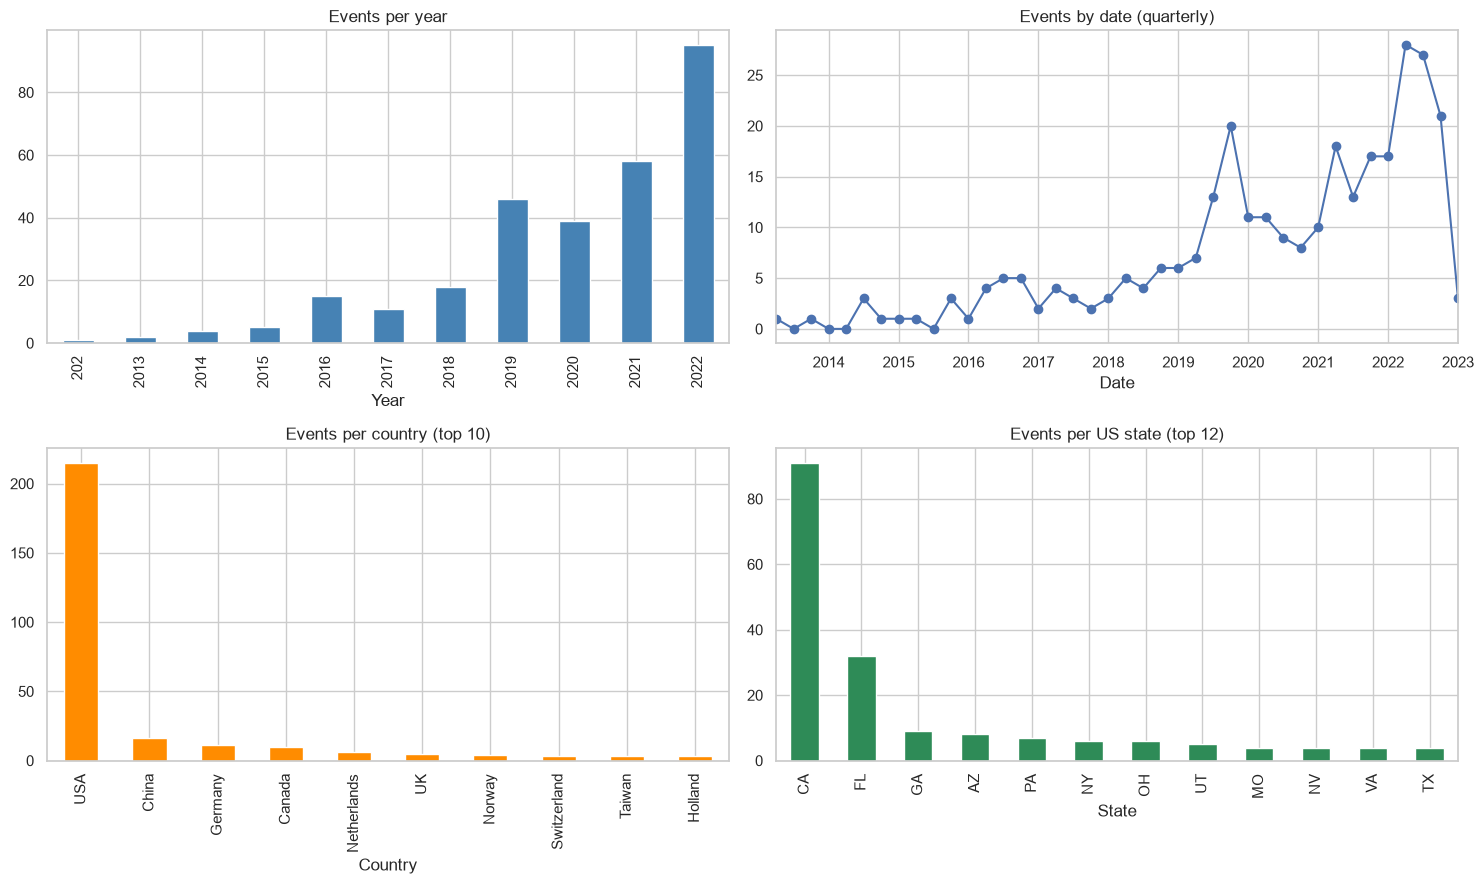

Year,202,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
Country,,,,,,,,,,,
USA,1,2,4,4,13,7,10,34,24,41,75
China,0,0,0,0,1,0,1,0,1,7,6
Germany,0,0,0,0,0,1,0,4,3,2,1
Canada,0,0,0,1,0,0,1,1,2,0,5
Netherlands,0,0,0,0,0,0,0,0,3,2,1
UK,0,0,0,0,0,0,0,0,0,2,3


distinct event days: 263 | max events on one day: 3 | days with >1 event: 28


dow,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
events by weekday,43,35,41,28,45,53,49


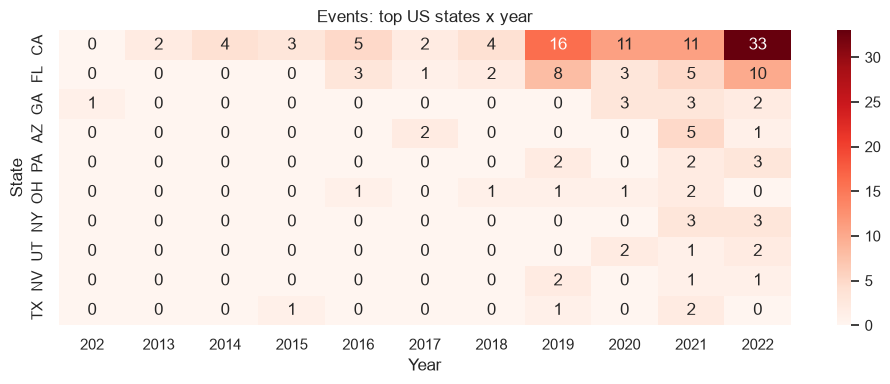

In [13]:
fig,ax=plt.subplots(2,2,figsize=(15,9))
t.groupby("Year").size().plot.bar(ax=ax[0,0],color="steelblue"); ax[0,0].set_title("Events per year")
t.set_index("Date").resample("QS").size().plot(ax=ax[0,1],marker="o"); ax[0,1].set_title("Events by date (quarterly)")
t.Country.value_counts().head(10).plot.bar(ax=ax[1,0],color="darkorange"); ax[1,0].set_title("Events per country (top 10)")
t[t.State!="Unknown"].State.value_counts().head(12).plot.bar(ax=ax[1,1],color="seagreen"); ax[1,1].set_title("Events per US state (top 12)")
save("06_tesla_events")
display(t.pivot_table(index="Country",columns="Year",values="Case #",aggfunc="count",fill_value=0).loc[t.Country.value_counts().head(6).index])
perday=t.groupby("Date").size(); print("distinct event days:",len(perday),"| max events on one day:",perday.max(),"| days with >1 event:",int((perday>1).sum()))
d_s=t.assign(dow=t.Date.dt.day_name()).groupby("dow").size().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]); display(d_s.to_frame("events by weekday").T)
plt.figure(figsize=(10,4)); sns.heatmap(t[t.State!="Unknown"].pivot_table(index="State",columns="Year",values="Case #",aggfunc="count",fill_value=0).loc[lambda x:x.sum(1).sort_values(ascending=False).head(10).index],annot=True,fmt="d",cmap="Reds"); plt.title("Events: top US states x year"); save("07_state_year_heatmap")

**Interpretation.** There are 294 events after removing 13 footer rows (the 4 duplicated rows reported earlier were empty footer rows, so no event was duplicated). Events per year rise sharply from 2019 and peak in 2022; the USA accounts for about 215 events, then China, Germany and Canada. California and Florida lead the US states. One record has a Year typo (202); date-based analysis uses the Date column. Events are spread across all weekdays, with Saturday and Sunday the highest, and 263 distinct event days, 28 of which had more than one event.

### 2b. Aspects of the death events

Events analysed: 294
Deaths per accident distribution:


Deaths,1.0,2.0,3.0,4.0
events,247,38,6,3


Total deaths: 353 | mean per event 1.20
Times a Tesla driver died (events): 117 | driver deaths in total: 117
Times a Tesla occupant (non-driver) died (events): 43
Proportion of events with >=1 Tesla occupant/driver death: 47.3%
Events where the vehicle hit a cyclist/pedestrian (death): 44 (15.0%)


Cyclists/ Peds,0.0,1.0,2.0
events,250,42,2


Events with an occupant/driver death AND a cyclist/pedestrian death: 1
Events involving a collision with another vehicle (death in other vehicle): 110 (37.4%)


Other vehicle,0.0,1.0,2.0,3.0,4.0
events,184,95,11,3,1


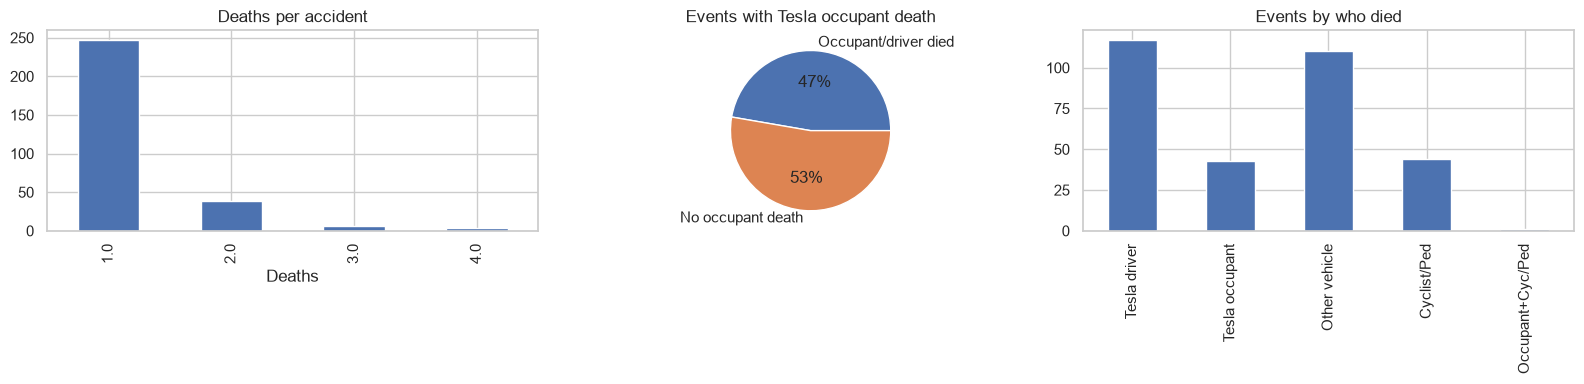

In [14]:
ev=len(t); occ=(t["Tesla driver"]>0)|(t["Tesla occupant"]>0); cyc=t["Cyclists/ Peds"]>0
print("Events analysed:",ev)
print("Deaths per accident distribution:"); display(t.Deaths.value_counts().sort_index().to_frame("events").T)
print("Total deaths: %d | mean per event %.2f"%(t.Deaths.sum(),t.Deaths.mean()))
print("Times a Tesla driver died (events):",int((t["Tesla driver"]>0).sum()),"| driver deaths in total:",int(t["Tesla driver"].sum()))
print("Times a Tesla occupant (non-driver) died (events):",int((t["Tesla occupant"]>0).sum()))
print("Proportion of events with >=1 Tesla occupant/driver death: %.1f%%"%(100*occ.mean()))
print("Events where the vehicle hit a cyclist/pedestrian (death):",int(cyc.sum()),"(%.1f%%)"%(100*cyc.mean())); display(t["Cyclists/ Peds"].value_counts().sort_index().to_frame("events").T)
print("Events with an occupant/driver death AND a cyclist/pedestrian death:",int((occ&cyc).sum()))
print("Events involving a collision with another vehicle (death in other vehicle):",int((t["Other vehicle"]>0).sum()),"(%.1f%%)"%(100*(t["Other vehicle"]>0).mean())); display(t["Other vehicle"].value_counts().sort_index().to_frame("events").T)
fig,ax=plt.subplots(1,3,figsize=(16,4))
t.Deaths.value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title("Deaths per accident")
pd.Series({"Occupant/driver died":int(occ.sum()),"No occupant death":int((~occ).sum())}).plot.pie(ax=ax[1],autopct="%1.0f%%"); ax[1].set_ylabel(""); ax[1].set_title("Events with Tesla occupant death")
pd.Series({"Tesla driver":int((t["Tesla driver"]>0).sum()),"Tesla occupant":int((t["Tesla occupant"]>0).sum()),"Other vehicle":int((t["Other vehicle"]>0).sum()),"Cyclist/Ped":int(cyc.sum()),"Occupant+Cyc/Ped":int((occ&cyc).sum())}).plot.bar(ax=ax[2]); ax[2].set_title("Events by who died")
save("08_tesla_deaths_aspects")

**Interpretation.** Most events (247 of 294) have one death; the 294 events cover 353 deaths (mean 1.2 per event). A Tesla driver died in 117 events and a non-driver Tesla occupant in 43, so a Tesla occupant or driver died in about 47% of events. A cyclist or pedestrian died in 44 events (15%), and an occupant or driver died together with a cyclist/pedestrian in only 1 event. Another vehicle was involved (a death in the other vehicle) in 110 events (about 37%).

### 2c. Event distribution across Tesla models
### 2d. Distribution of verified Tesla autopilot deaths

Model,Unknown,S,3,X,Y,1,2
events,181,45,39,17,10,1,1


Events with verified autopilot deaths: 16 | total verified autopilot deaths: 19 | autopilot claimed events: 35


Verified Tesla Autopilot Deaths,0.0,1.0,2.0
events,278,13,3


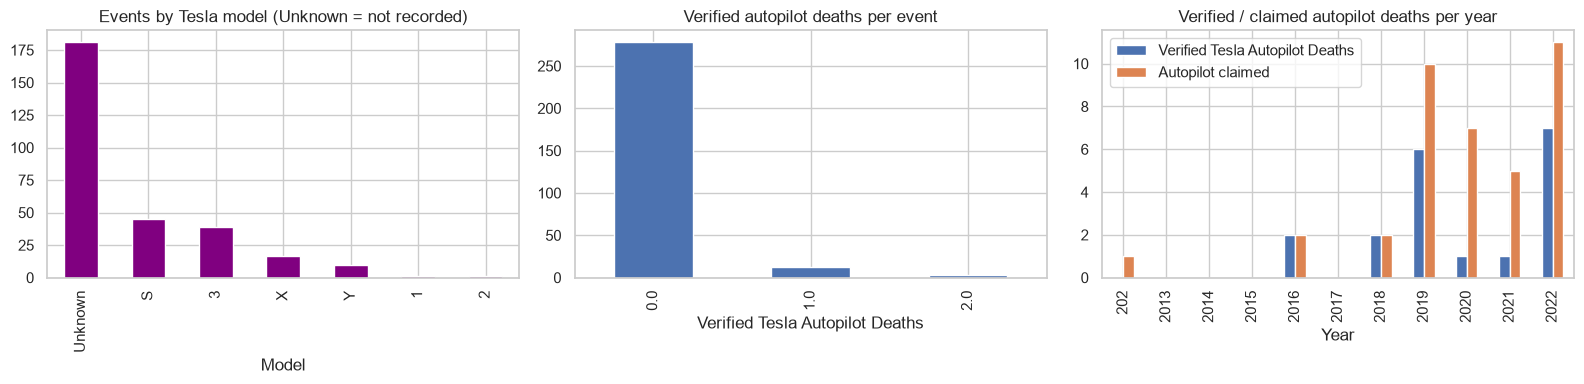

Notebook run time: 28.1 min


In [15]:
mod=t.Model.value_counts(); display(mod.to_frame("events").T)
vap=t["Verified Tesla Autopilot Deaths"]; print("Events with verified autopilot deaths:",int((vap>0).sum()),"| total verified autopilot deaths:",int(vap.sum()),"| autopilot claimed events:",int((t["Autopilot claimed"]>0).sum()))
display(vap.value_counts().sort_index().to_frame("events").T)
fig,ax=plt.subplots(1,3,figsize=(16,4))
mod.plot.bar(ax=ax[0],color="purple"); ax[0].set_title("Events by Tesla model (Unknown = not recorded)")
vap.value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Verified autopilot deaths per event")
t.groupby("Year")[["Verified Tesla Autopilot Deaths","Autopilot claimed"]].sum().plot.bar(ax=ax[2]); ax[2].set_title("Verified / claimed autopilot deaths per year")
save("09_models_autopilot")
print("Notebook run time: %.1f min"%((time.time()-T0)/60))

**Interpretation.** The Tesla model is unknown for 181 events; among known models, Model S (45) and Model 3 (39) have the most events, followed by X (17) and Y (10). Verified autopilot deaths occurred in 16 events (19 deaths in total; 13 events with one death), while autopilot was claimed in 35 events. Verified autopilot deaths are a small fraction (about 5%) of all events, so conclusions about autopilot safety need exposure (miles driven) data that this file does not contain.

## Conclusions
Part 1: a pretrained-MobileNetV2 YOLO-style detector trained on CPU reaches mAP@0.5 of about 0.20 on held-out test images, detecting frequent vehicle types reliably and struggling with rare classes and small objects; it is a working baseline, not a production model. Part 2: Tesla-related death events grew strongly until 2022, are concentrated in the USA (especially California and Florida), usually involve one death, and in about 47% of events a Tesla driver or occupant died; verified autopilot deaths are a small share of the recorded events.